## Import packages

In [8]:
#Import
from pathlib import Path
from collections import Counter
import pandas as pd
from helpers import *
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt

# Load data
clean_data = pd.read_excel("customers_sales_with_dxf_data.xlsx")
clean_data.head(5)

,customer_name,customer_branch,file_name,order_quantity,customer_name_original,customer_branch_original,bounding_box_width,bounding_box_height,bounding_box_area,cutting_length,num_holes,rectangularity
0,MetalForm SA,Frankfurt Branch,Geo (1).DXF,1600,MetalForm SA,Frankfurt Branch,1600.219048,305.140135,488291.056038,3438.024977,0,0.082199
1,AutoParts AG,Munich Branch,Geo (10).DXF,9650,AutoParts AG,Munich Branch,853.830000,333.401400,284668.117362,3217.207505,5,0.724271
2,PrecisionCut GmbH,Stuttgart Branch,Geo (11).DXF,7800,PrecisionCut GmbH,Stuttgart Branch,164.000000,145.120000,23799.680000,1742.517642,7,0.600032
3,PrecisionCut GmbH,Stuttgart Branch,Geo (15).DXF,4000,PrecisionCut GmbH,Stuttgart Branch,193.800891,138.442589,26830.297074,1302.774283,2,0.685885
4,AutoParts AG,Berlin Branch,Geo (12).DXF,8800,AutoParts AG,Berlin Branch,937.150697,74.006665,69355.398059,2764.783512,11,0.865878


## Relevant measures that should be checked for outliers
#### (findings of univariate, bivariate & multivariate analysis):
1. (order quantity)
2. bounding box height
3. cutting length
4. (bounding box area)
5. number of holes (geo 54)
6. rectangularity?

## 1. Check outliers of order quantity

                order quantity
q25                     4000.0
q75                     9050.0
min                      500.0
max                    19700.0
range                  19200.0
iqr                     5050.0
n_outliers_iqr             6.0


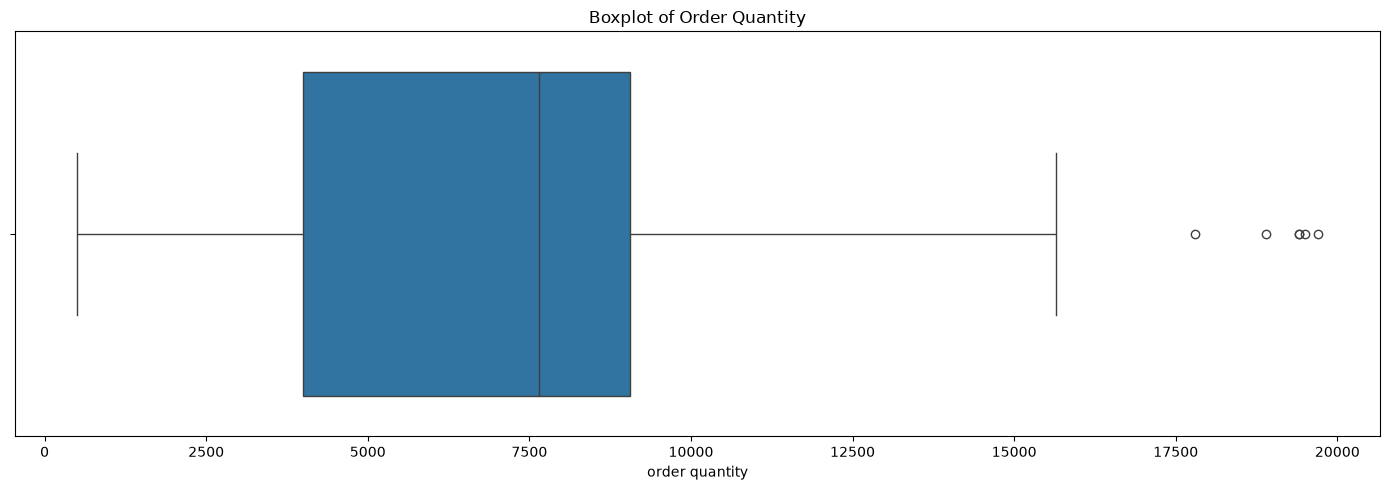

In [ ]:
# Calculate quantity statistics
quantities = clean_data["order_quantity"].dropna()
q1, q3 = quantities.quantile(0.25), quantities.quantile(0.75)
iqr = q3 - q1

quantity_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": quantities.min(),
    "max": quantities.max(),
    "range": quantities.max() - quantities.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((quantities < q1 - 1.5 * iqr) | (quantities > q3 + 1.5 * iqr)).sum(),
})

print(round(quantity_statistics.to_frame(name="order quantity"), 2))


# Visualize the order quantity statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=quantities, ax=ax)
ax.set_title("Boxplot of Order Quantity")
ax.set_xlabel("order quantity")

plt.tight_layout()
plt.show()



In [29]:
for i, quant in enumerate(quantities):
    if (quant < q1 - 1.5 * iqr) or (quant > q3 + 1.5 * iqr):
        print(clean_data["file_name"].iloc[i])

Geo (30).DXF
Geo (32).DXF
Geo (35).DXF
Geo (60).DXF
Geo (61).DXF
Geo (63).DXF


## 2. Check outliers of bounding box height

                bounding box height
q25                           70.31
q75                          312.83
min                           12.11
max                         1193.26
range                       1181.15
iqr                          242.52
n_outliers_iqr                 7.00


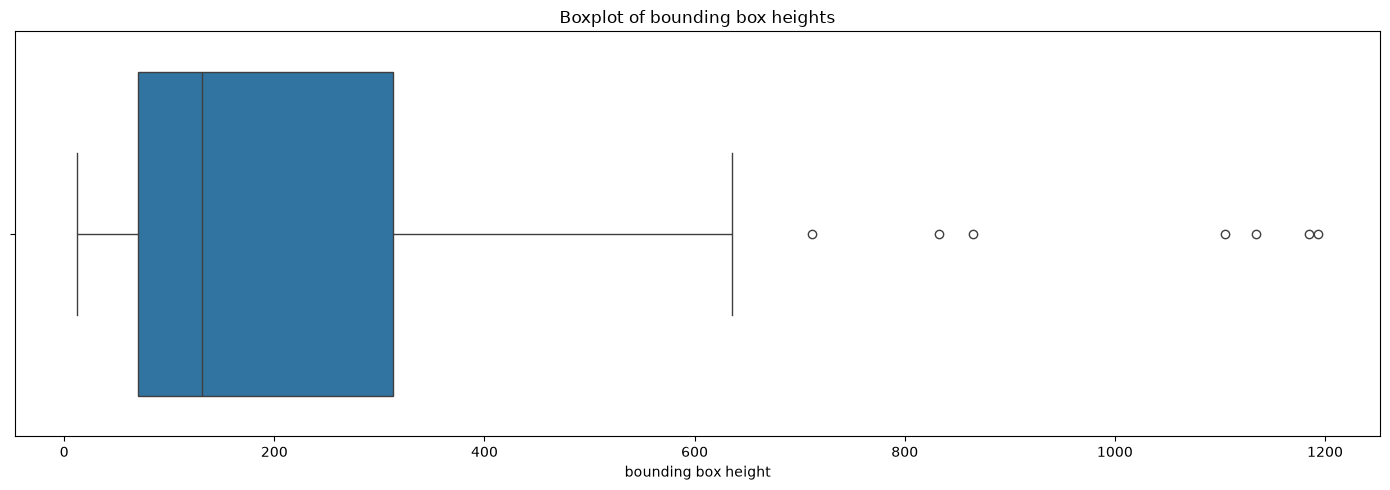

In [32]:
# Calculate height statistics
heights = clean_data["bounding_box_height"].dropna()
q1, q3 = heights.quantile(0.25), heights.quantile(0.75)
iqr = q3 - q1

height_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": heights.min(),
    "max": heights.max(),
    "range": heights.max() - heights.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((heights < q1 - 1.5 * iqr) | (heights > q3 + 1.5 * iqr)).sum(),
})

print(round(height_statistics.to_frame(name="bounding box height"), 2))


# Visualize the order quantity statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=heights, ax=ax)
ax.set_title("Boxplot of bounding box heights")
ax.set_xlabel("bounding box height")

plt.tight_layout()
plt.show()

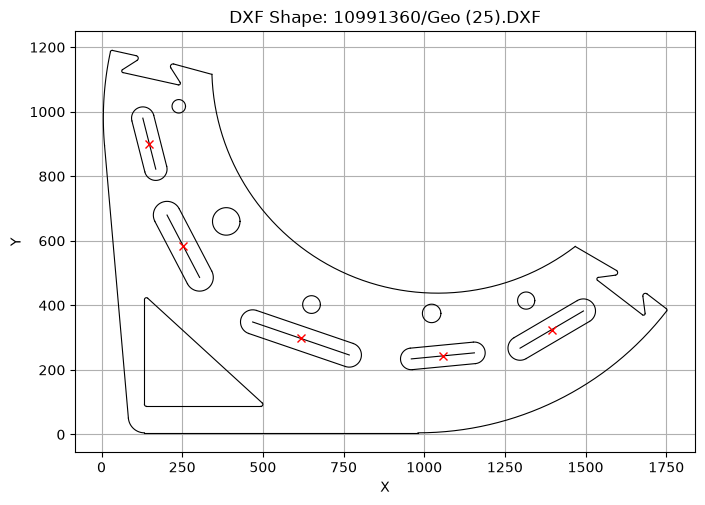

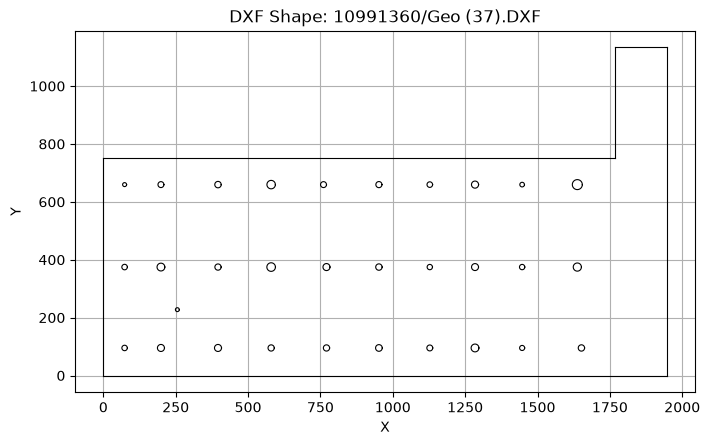

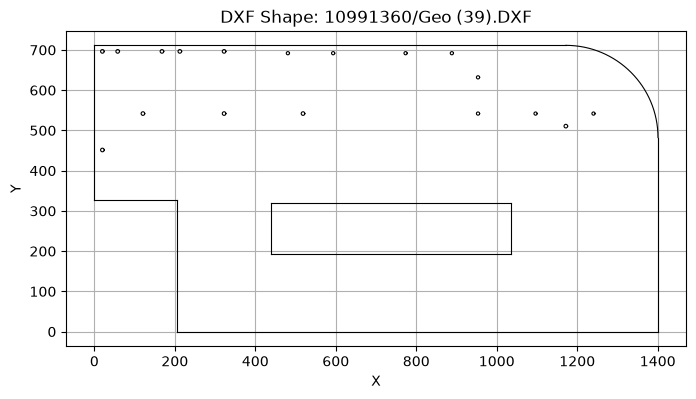

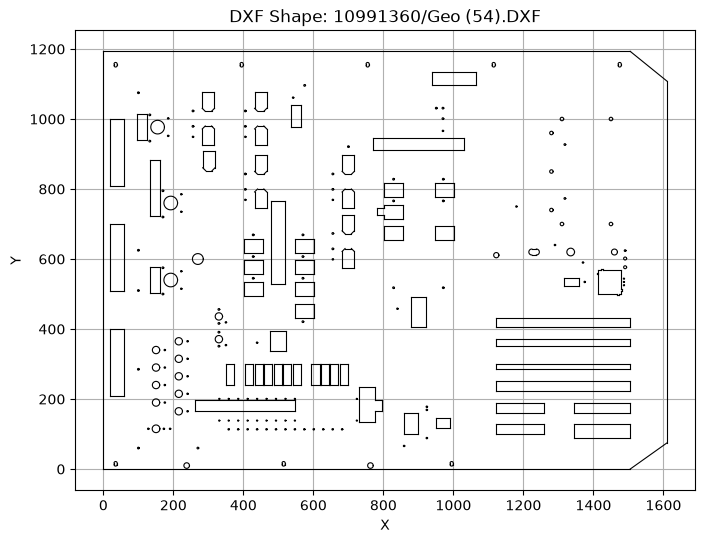

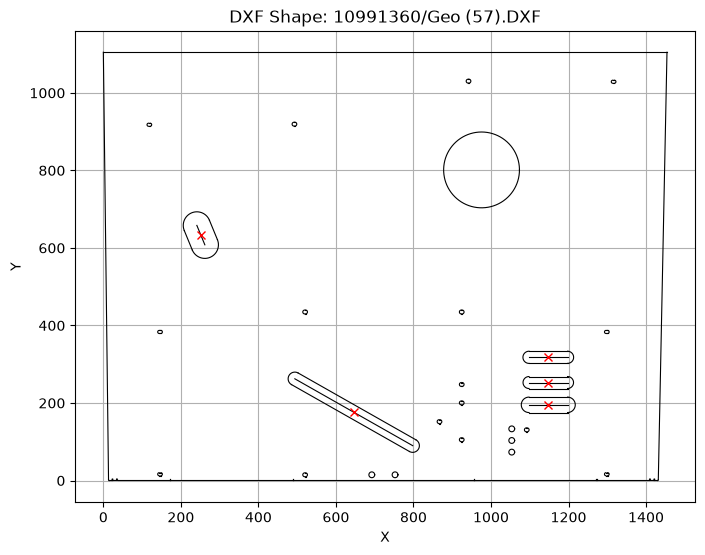

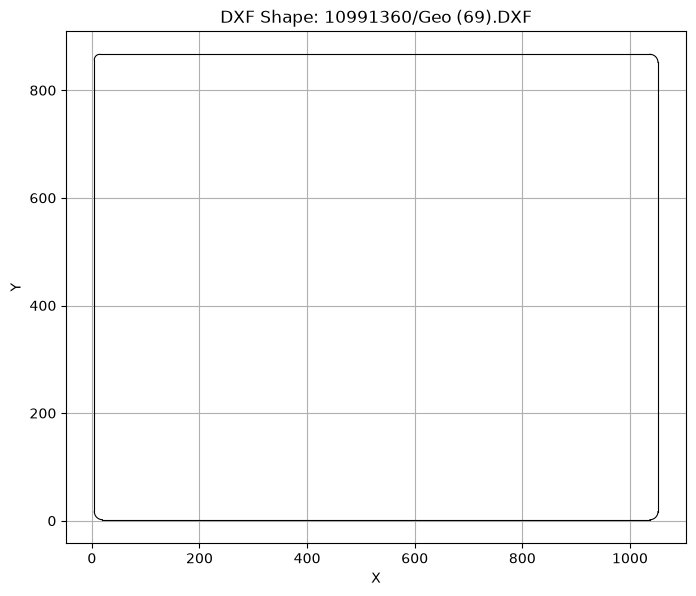

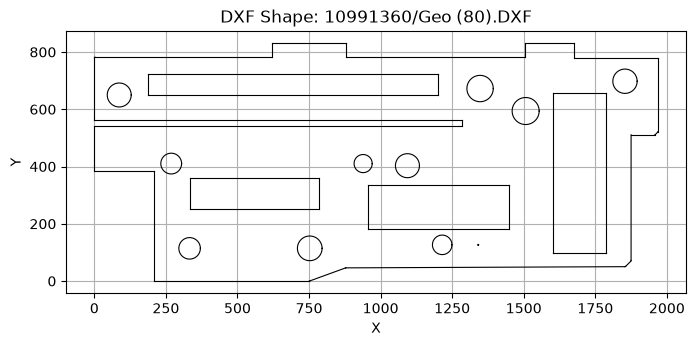

In [35]:
for i, height in enumerate(heights):
    if (height < q1 - 1.5 * iqr) or (height > q3 + 1.5 * iqr):
        plot_dxf("10991360/" + clean_data["file_name"].iloc[i])

## 2. Check outliers of cutting length

                cutting length
q25                     775.30
q75                    3711.43
min                     100.96
max                   26007.87
range                 25906.91
iqr                    2936.13
n_outliers_iqr            6.00


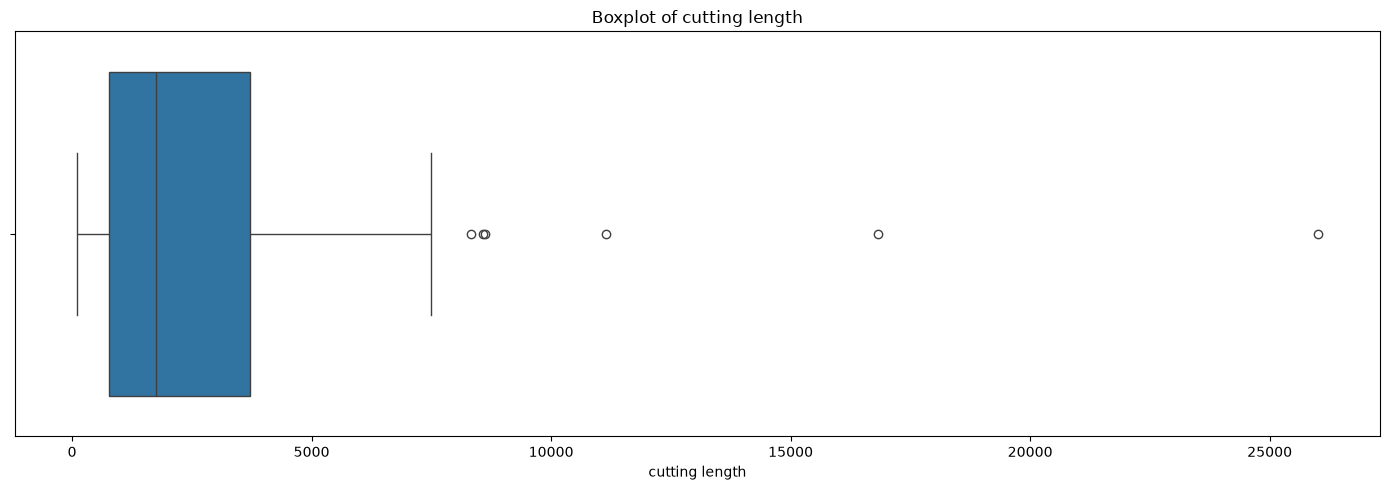

In [37]:
# Calculate height statistics
cutting_lengths = clean_data["cutting_length"].dropna()
q1, q3 = cutting_lengths.quantile(0.25), cutting_lengths.quantile(0.75)
iqr = q3 - q1

cutting_length_statistics = pd.Series({
    "q25": q1,
    "q75": q3,
    "min": cutting_lengths.min(),
    "max": cutting_lengths.max(),
    "range": cutting_lengths.max() - cutting_lengths.min(),
    "iqr": iqr,
    "n_outliers_iqr": ((cutting_lengths < q1 - 1.5 * iqr) | (cutting_lengths > q3 + 1.5 * iqr)).sum(),
})

print(round(cutting_length_statistics.to_frame(name="cutting length"), 2))


# Visualize the order quantity statistics in a boxplot
fig, ax = plt.subplots(1, 1, figsize=(14, 5))

sns.boxplot(x=cutting_lengths, ax=ax)
ax.set_title("Boxplot of cutting length")
ax.set_xlabel("cutting length")

plt.tight_layout()
plt.show()

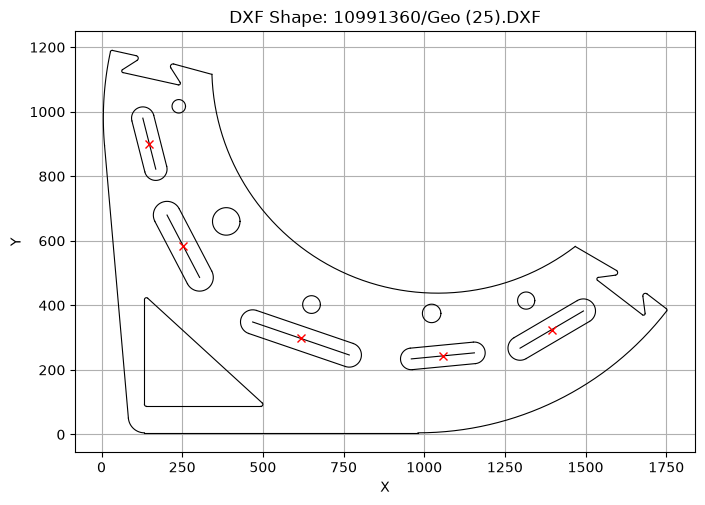

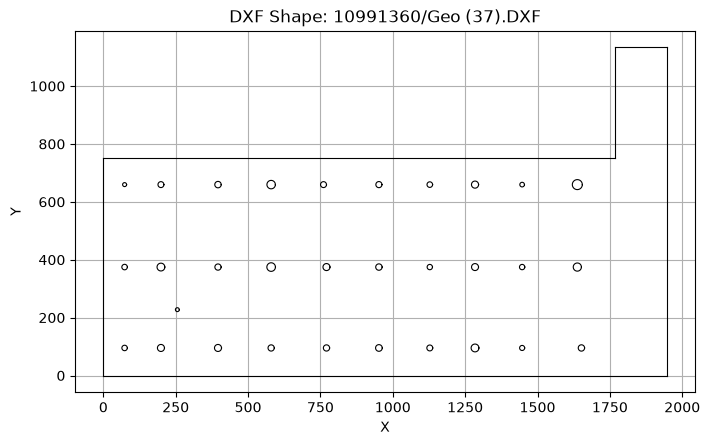

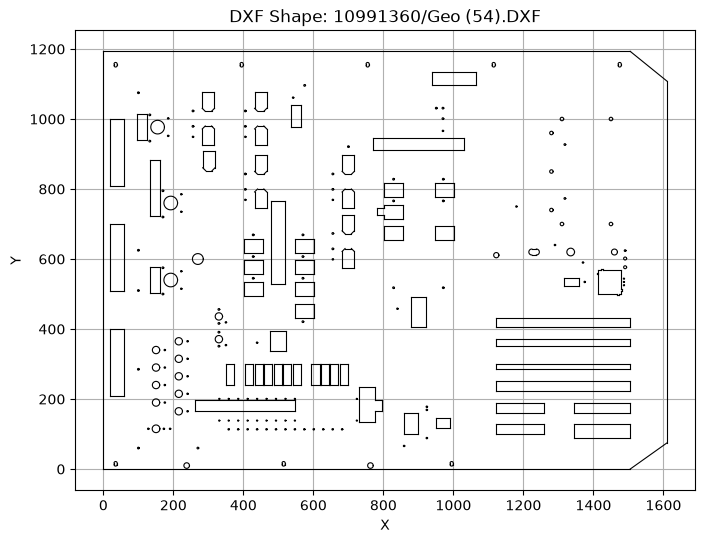

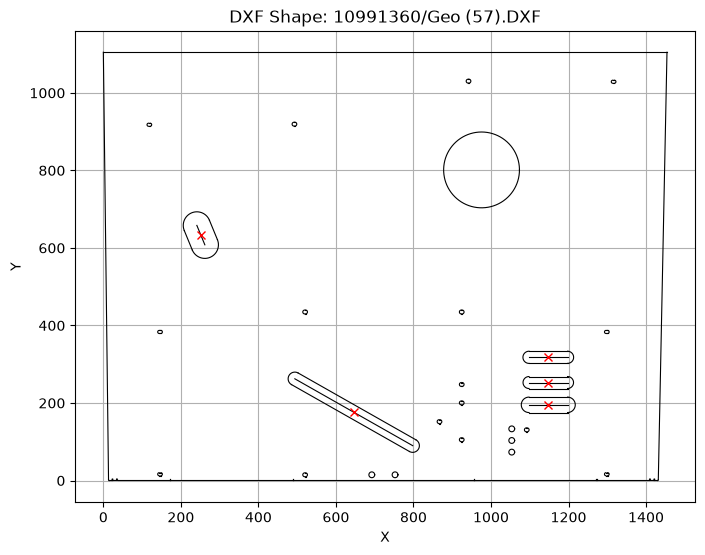

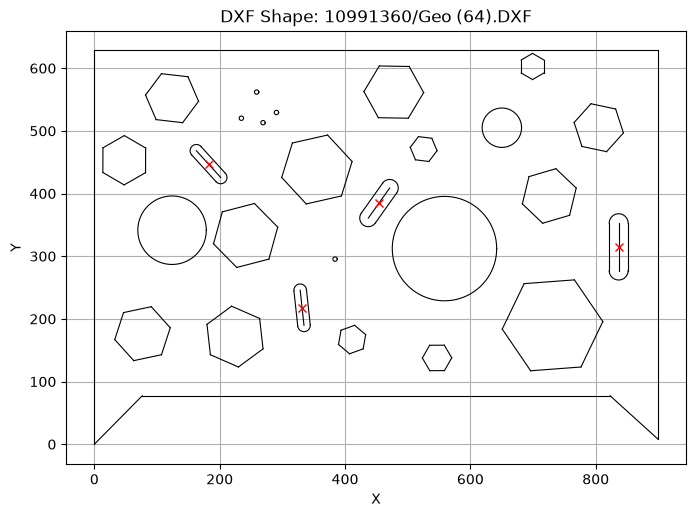

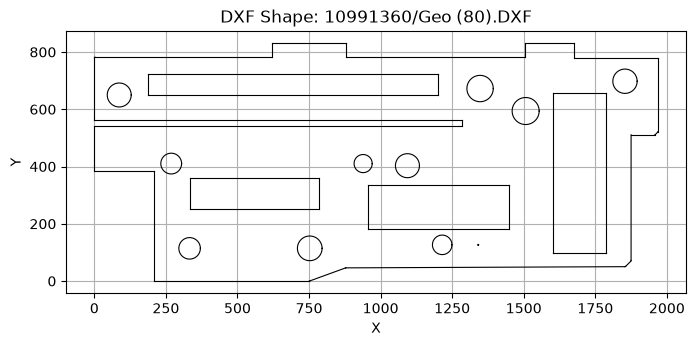

In [38]:
for i, length in enumerate(cutting_lengths):
    if (length < q1 - 1.5 * iqr) or (length > q3 + 1.5 * iqr):
        plot_dxf("10991360/" + clean_data["file_name"].iloc[i])